# Laboratorio 7 — Task 1.1 y Task 1.2
Grupo 3: $q=0.30$, $D=5$ días.

# Task 1.1 — Predicciones
Escritas desde el análisis del SD y de M/M/$c$, sin correr el híbrido. Se entregan sin modificar.

**a. Híbrido con retroalimentación contra cascada.**
- $U(100)$: casi igual en ambos, cerca de 19,800. El equilibrio de Bass con $\delta_0$ es 19,801 y, con $c=8$, $\rho=0.625$ a $U=M$, así que al final el abandono extra es 0.
- Latencia máxima: mucho menor con lazo cerrado que en cascada (del orden de 1 s contra varios segundos). Sin lazo, $U$ sigue creciendo mientras el clúster está saturado.
- Fracción rechazada máxima: cerca de 0 con lazo y de pocos por ciento en cascada. El abandono frena a $U$ justo cuando $\rho\to1$.

**b. Primer pedido y servidores.**
- Con $W<W_{ok}$, $U$ sigue el SD con $\delta_0$ hasta $U=\theta c\mu/a=11{,}200$. Eso ocurre hacia el **día 16**.
- Llegan 2 servidores el día 21. Con $c=6$ el umbral es $U=16{,}800$, y se pide otro lote hacia el día 22–25.
- En el día 100: **$c=8$**. Con $c=8$ el umbral sería $U=22{,}400>M$, así que no hay más pedidos.

**c. De $H=1$ a $H=7$.**
- Cambia la **latencia máxima** (y con ella el rechazo máximo): crece, porque $W$ y $r$ quedan congelados hasta 7 días y el DES se entera tarde de que llegaron servidores o de que $U$ creció.
- $U(100)$ cambia poco, porque el equilibrio final no depende de $H$.
- Espero un cambio **irregular**, no monótono. Depende de dónde caen la llegada de servidores ($\approx$ día 21) y el cruce respecto de los múltiplos de $H$, y además hay ruido del DES en cada intercambio.

---
# Task 1.2 — Equilibrio con capacidad fija ($c=4$, sin rechazos)

In [1]:
import numpy as np, matplotlib.pyplot as plt
from math import factorial
from scipy.optimize import brentq
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
p, q, M, d0, kW, kR, Wok = 0.002, 0.30, 20000., 0.003, 1.0, 0.5, 0.75
a, mu, c = 0.0005, 2.0, 4

def erlang_c(c, A):
    """C(c,A): probabilidad de esperar en M/M/c (fórmula de Erlang C)."""
    s = sum(A**k/factorial(k) for k in range(c))
    tc = A**c/factorial(c)*c/(c - A)
    return tc/(s + tc)

def W_mmc(U):
    """Task 1.2a: W = C(c,A)/(c*mu - a*U) + 1/mu, con A = a*U/mu. Válida para a*U < c*mu, es decir U < 16,000."""
    A = a*U/mu
    return erlang_c(c, A)/(c*mu - a*U) + 1/mu

def f_eq(U):
    """Task 1.2b: adopción neta menos abandono, con la latencia de M/M/4 y r = 0."""
    delta = d0 + kW*max(0.0, W_mmc(U) - Wok)
    return (p + q*U/M)*(M - U) - delta*U

print("Validez: a*U < c*mu  ->  U <", c*mu/a)
for U in [100, 5000, 10000, 12000, 14000, 15000, 15900]:
    print(f"U={U:>6}: A={a*U/mu:.3f}  rho={a*U/(c*mu):.3f}  C={erlang_c(c, a*U/mu):.4f}  W={W_mmc(U):.4f} s   f(U)={f_eq(U):>12.1f}")

Validez: a*U < c*mu  ->  U < 16000.0
U=   100: A=0.025  rho=0.006  C=0.0000  W=0.5000 s   f(U)=        69.4
U=  5000: A=1.250  rho=0.312  C=0.0422  W=0.5077 s   f(U)=      1140.0
U= 10000: A=2.500  rho=0.625  C=0.3199  W=0.6066 s   f(U)=      1490.0
U= 12000: A=3.000  rho=0.750  C=0.5094  W=0.7547 s   f(U)=      1363.4
U= 14000: A=3.500  rho=0.875  C=0.7379  W=1.2379 s   f(U)=     -5600.1
U= 15000: A=3.750  rho=0.938  C=0.8650  W=2.2301 s   f(U)=    -21110.9
U= 15900: A=3.975  rho=0.994  C=0.9862  W=20.2234 s   f(U)=   -308688.4


In [2]:
Us = np.linspace(100, 15990, 4000); fs = np.array([f_eq(u) for u in Us])
idx = np.where(np.sign(fs[:-1]) != np.sign(fs[1:]))[0]
raices = [brentq(f_eq, Us[i], Us[i+1], xtol=1e-10) for i in idx]
Ustar = raices[0]; rho_star = a*Ustar/(c*mu); W_star = W_mmc(Ustar)
print(f"Raíces de f(U)=0 en (100, 16000): {raices}")
print(f"U* = {Ustar:.2f}   rho = {rho_star:.4f}   W = {W_star:.4f} s   (W - Wok = {W_star - Wok:.4f} s)")
print(f"delta(U*) = {d0 + kW*(W_star - Wok):.5f} por día")
print(f"Bass con delta0 solo (sin retroalimentación): U* = {brentq(lambda U: (p + q*U/M)*(M - U) - d0*U, 100, 20000):.2f}")

Raíces de f(U)=0 en (100, 16000): [12715.507878244447]
U* = 12715.51   rho = 0.7947   W = 0.8574 s   (W - Wok = 0.1074 s)
delta(U*) = 0.11041 por día
Bass con delta0 solo (sin retroalimentación): U* = 19801.34


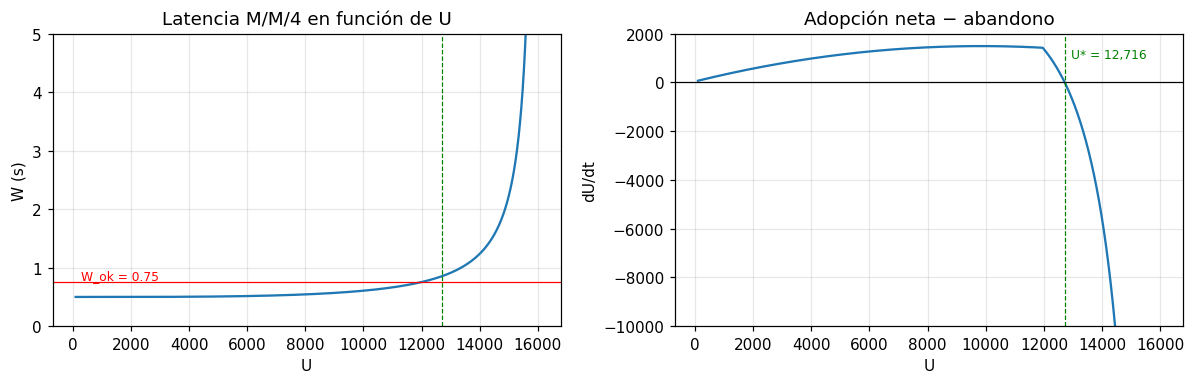

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(Us, [W_mmc(u) for u in Us]); ax[0].axhline(Wok, color='r', lw=.8); ax[0].axvline(Ustar, color='g', ls='--', lw=.8)
ax[0].set(xlabel='U', ylabel='W (s)', ylim=(0, 5), title='Latencia M/M/4 en función de U'); ax[0].text(300, .8, 'W_ok = 0.75', color='r', fontsize=8)
ax[1].plot(Us, fs); ax[1].axhline(0, color='k', lw=.8); ax[1].axvline(Ustar, color='g', ls='--', lw=.8)
ax[1].set(xlabel='U', ylabel='dU/dt', title='Adopción neta − abandono', ylim=(-1e4, 2e3)); ax[1].text(Ustar+200, 1000, f'U* = {Ustar:,.0f}', color='g', fontsize=8)
plt.tight_layout(); plt.savefig('fig_12.png', dpi=130); plt.show()